# Quarterback efficiency

Key metrics, all on **dropbacks** (passes, sacks and scrambles):

| Metric | Meaning |
|---|---|
| `epa_per_db` | EPA per dropback: overall production |
| `cpoe` | Completion % over expected, given throw depth, coverage, etc.: accuracy |
| `success_rate` | Share of dropbacks with positive EPA: consistency |
| `sack_rate` | Sacks per dropback |
| `composite` | Average of the EPA and CPOE z-scores among qualified QBs |

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays
pd.set_option("display.precision", 3)

SEASON = 2026  # change to 2025 to look back at the final season

In [2]:
from nfl_analytics import qb_stats

plays = offensive_plays(load_pbp(SEASON))
weeks = int(plays["week"].max())
through = "regular season" if weeks >= 18 else f"through week {weeks}"
min_db = 15 * weeks  # ~15 dropbacks per week played
qbs = qb_stats(plays, min_dropbacks=min_db)
qbs

,name,team,dropbacks,epa_per_db,total_epa,success_rate,cpoe,pass_tds,ints,sacks,sack_rate,composite
player_id,,,,,,,,,,,,
00-0034857,J.Allen,BUF,179,0.367,65.662,0.469,5.836,7.0,4.0,12.0,0.067,1.648
00-0037834,B.Purdy,SF,161,0.342,55.119,0.540,3.271,10.0,2.0,4.0,0.025,1.274
00-0036442,J.Burrow,CIN,162,0.240,38.828,0.519,6.644,10.0,2.0,6.0,0.037,1.399
00-0039851,D.Maye,NE,173,0.236,40.745,0.520,4.354,9.0,6.0,10.0,0.058,1.113
00-0036971,T.Lawrence,JAX,176,0.230,40.511,0.500,2.460,11.0,4.0,8.0,0.045,0.871
00-0033106,J.Goff,DET,129,0.227,29.239,0.488,-0.065,6.0,0.0,9.0,0.070,0.558
00-0039163,C.Stroud,HOU,209,0.221,46.160,0.517,4.566,8.0,1.0,9.0,0.043,1.099
00-0029604,K.Cousins,LV,189,0.217,40.970,0.503,-0.777,12.0,4.0,5.0,0.026,0.446
00-0039150,B.Young,CAR,182,0.212,38.561,0.451,2.506,9.0,2.0,10.0,0.055,0.827


## Ranked by composite (EPA + CPOE)

In [3]:
qbs.sort_values("composite", ascending=False)[["name", "team", "dropbacks", "epa_per_db", "cpoe", "composite"]].head(10)

,name,team,dropbacks,epa_per_db,cpoe,composite
player_id,,,,,,
00-0034857,J.Allen,BUF,179,0.367,5.836,1.648
00-0036442,J.Burrow,CIN,162,0.240,6.644,1.399
00-0037834,B.Purdy,SF,161,0.342,3.271,1.274
00-0039851,D.Maye,NE,173,0.236,4.354,1.113
00-0039163,C.Stroud,HOU,209,0.221,4.566,1.099
00-0036971,T.Lawrence,JAX,176,0.230,2.460,0.871
00-0039150,B.Young,CAR,182,0.212,2.506,0.827
00-0033873,P.Mahomes,KC,147,0.203,1.590,0.692
00-0039910,J.Daniels,WAS,124,0.069,3.978,0.616


## Accuracy vs. production

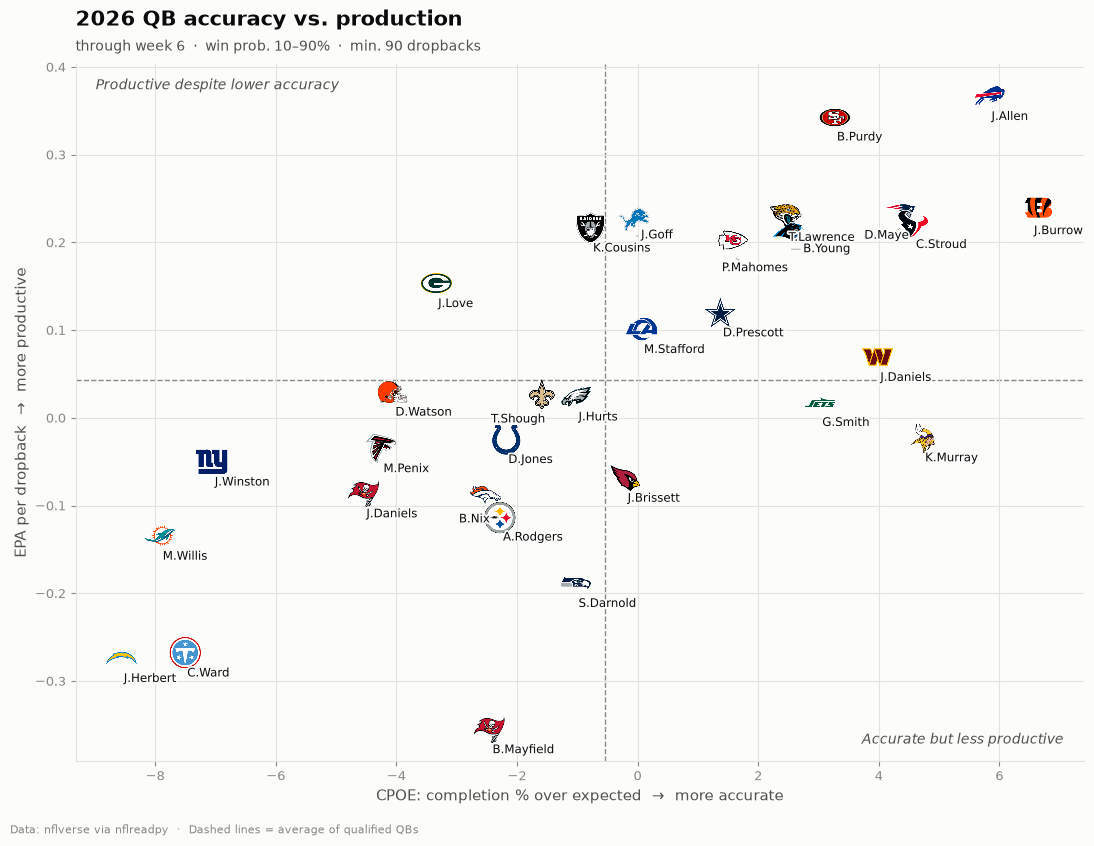

In [4]:
from nfl_analytics import plot_epa_vs_cpoe, plot_epa_ranking

subtitle = f"{through}  ·  win prob. 10–90%  ·  min. {min_db} dropbacks"
fig, ax = plot_epa_vs_cpoe(qbs, title=f"{SEASON} QB accuracy vs. production", subtitle=subtitle)

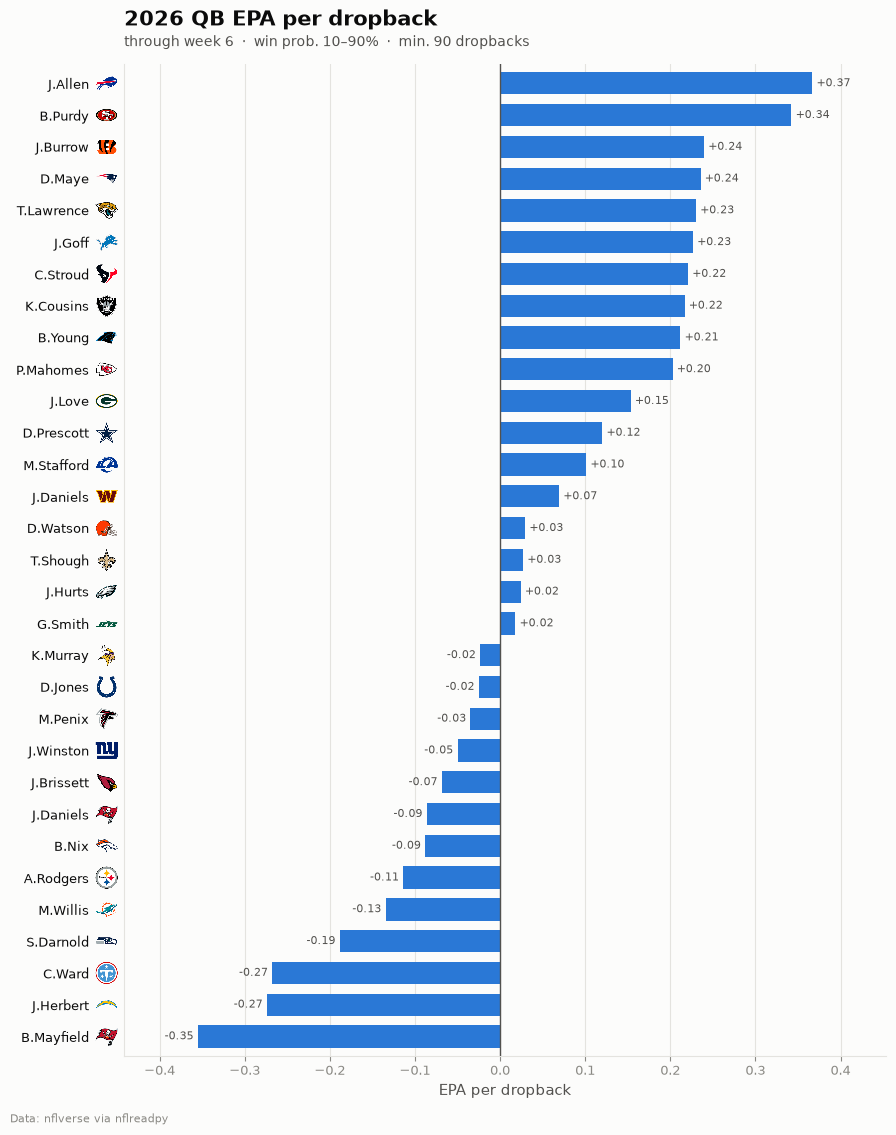

In [5]:
fig, ax = plot_epa_ranking(qbs, title=f"{SEASON} QB EPA per dropback", subtitle=subtitle)

## Ideas to explore next
- **Stability:** load two seasons and correlate each QB's EPA and CPOE year over year. Which metric holds up?
- **Situational splits:** 3rd down, red zone, play-action.
- **Time to throw:** does holding the ball longer cause pressure? (`time_to_throw` in participation data)
- **Air yards vs. YAC:** `air_epa` vs. `yac_epa` shows who creates value downfield.
- **Weekly trend:** rolling EPA/dropback by week for one QB.